# From a research idea to a backtested signal

**This notebook uses NVIDIA open-weight models to generate a labelled dataset you can test a
strategy on, built from Bigdata.com news and earnings calls and labelled entirely on your own
GPUs: a 120B reasoning teacher and a 4B student distilled from its judgement, with the retrieved
text and its labels kept inside your compute environment.**

The search first retrieves every passage that discusses your theme. The teacher labels a sample
of them, the student learns from those labels and then labels the entire corpus at the speed and
cost of a small model, with the judgement of a large one. That is the whole point of distilling,
and it is what turns a sample into a dataset.

The backtest at the end puts that dataset to the test. It turns the labels into positions and
measures how much value they actually carry, against a floor built without any labels at all.

You bring the question: a theme, the sentences to search for, written both ways round, and a
prompt that defines each label. Everything after that is here.

## Research Idea: Market Share

*Is this company taking business from its competitors, or giving it away?*

Thirty seed sentences a side, four of them:

- *Company gained share in its core market at the expense of competitors*
- *Win rates against competitors improved meaningfully this period*
- *Company lost ground to competitors in its primary end market*
- *Incumbents are taking back wallet share as the firm offering loses its edge*

The prompt asks for **`gainer`** (long), **`loser`** (short), or **`irrelevant`**.

### Running a different theme

To ask another question, pricing power for example, change two things in
`config/data_extraction.yaml` before Part 1:

1. **`theme:`**, the question itself. `id` and `title` name it. `classes` lists the labels
   and which way each one trades: `1` is long, `-1` is short, and the label with no value
   is the one that carries no position. `body` is the prompt: what each label means, in
   plain language.
2. **`seeds.statements`**, the sentences the search looks for: `positive` for one side of
   the theme, `negative` for the other.

Nothing else changes. The rest of the notebook runs as it is.

## The pipeline

| part | what happens |
|---|---|
| **1. Retrieval** | ten years of news and transcripts, 2016-2026, across the Russell 1000 point in time, ranked against your seeds |
| **2. Labelling** | a 120B model labels a sample, a 4B model learns from it and labels the whole corpus |
| **3. Signal** | is the signal predictive — information coefficient against forward returns |
| **4. Backtest** | the labels become a long/short book, measured against a no-label floor |

The retrieved text and the generated labels remain inside your compute environment.
Everything that reads your corpus runs on your own GPUs: the encoder that ranks the retrieved
passages, the 120B teacher, the fine-tuning, and the labelling of every passage.

What does reach outside:

| external | used for | when |
|---|---|---|
| Bigdata.com | the search | Part 1 |
| model and container registries | weights and serving images | setup |

Parts 3 and 4 need daily returns, and they read them from a price cache **you** put on disk.


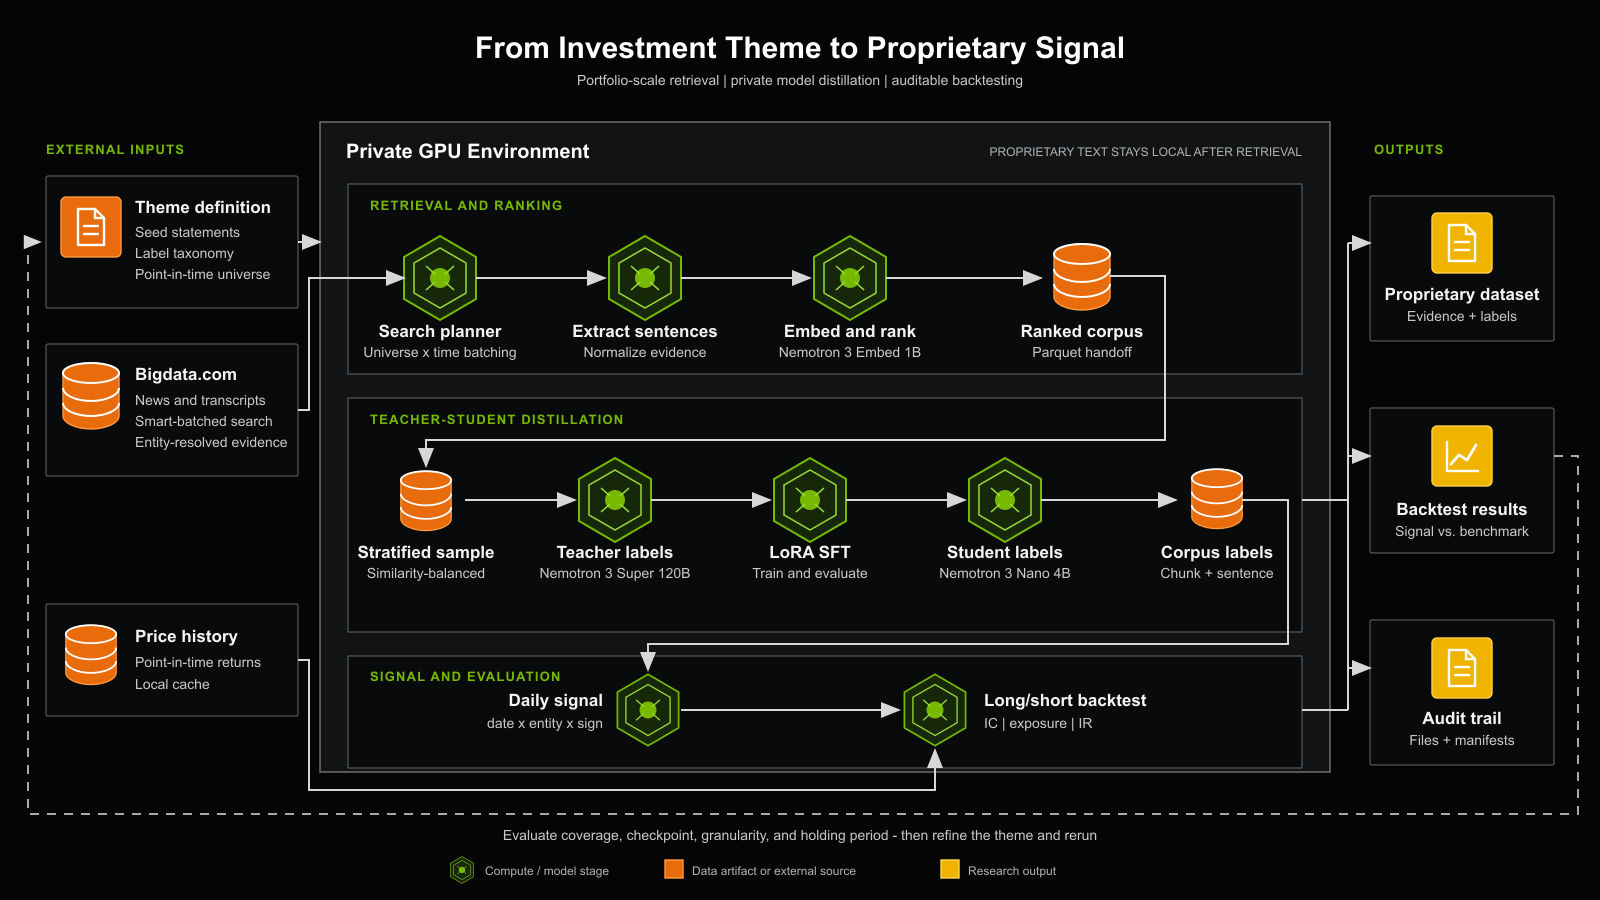

## 0. Setup

Set the environment up first: see **Setup** in [README.md](../README.md), then select
`.venv/bin/python`, the repository's own environment, as the kernel.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Image, display

from distill import driver

# Accepts either notebooks/ or the root, so re-running this cell after the chdir is safe.
REPO_ROOT = next(d for d in (Path.cwd(), Path.cwd().parent)
                 if (d / "src").is_dir() and (d / "config").is_dir())
CONFIG    = REPO_ROOT / "config"
RUN       = REPO_ROOT / "output"

os.chdir(REPO_ROOT)
os.environ["PATH"] = f"{REPO_ROOT}/.venv/bin:{os.environ['PATH']}"
os.environ["REPO_ROOT"] = str(REPO_ROOT)
os.environ["RUN"] = str(RUN)
os.environ["CONFIG"] = str(CONFIG)

THEME_TITLE = (yaml.safe_load((CONFIG / "data_extraction.yaml")
               .read_text())["theme"]["title"])

print("config :", CONFIG)
print("output :", RUN, "(exists:", RUN.is_dir(), ")")

config : /work/bigdata-dataset-generation/config
output : /work/bigdata-dataset-generation/output (exists: True )


### 0.1 Check the config

`check-config` reads the two files in `config/` and stops on anything missing, rather than
starting a run that dies halfway.

In [2]:
%%bash
distill check-config

  WARNING  input not found: /work/bigdata-dataset-generation/output/similarity/combinations_with_similarity.parquet
config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output

config valid: both files present, classes gainer, loser, irrelevant
prompts chunk d75a8d22e5b5fe23, sentence d64c93d7097cc760

10 of 11 stages have not run yet, starting with `subset`:
  - input not found: output/similarity/combinations_with_similarity.parquet


### 0.2 Download the models

The encoder Part 1 ranks with, and the two models Part 2 labels with. They come from Hugging
Face once, and land in `models/`, beside `config/` and `output/`. Each one is pinned to the
revision of the reference run, so a later upload under the same name changes nothing here.

No credentials needed. All three are public and ungated, so the download runs
anonymously. An `HF_TOKEN` in `.env` is optional, and only raises the rate limit
Hugging Face applies to anonymous traffic.

In [3]:
%%bash
HF_HUB_CACHE=./models hf download nvidia/Nemotron-3-Embed-1B-BF16 \
    --revision c0c9fea93ea424587517f2c59e20db9f1d6bf615
HF_HUB_CACHE=./models hf download nvidia/NVIDIA-Nemotron-3-Super-120B-A12B-NVFP4 \
    --revision ff433f5493e25d631c9f12b5d55c674229923d02
HF_HUB_CACHE=./models hf download nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16 \
    --revision dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f
du -sh models/

Fetching 15 files: 100%|██████████| 15/15 [00:00<00:00, 781.12it/s]


✓ Downloaded
  path: /work/bigdata-dataset-generation/models/models--nvidia--Nemotron-3-Embed-1B-BF16/snapshots/c0c9fea93ea424587517f2c59e20db9f1d6bf615


Fetching 36 files: 100%|██████████| 36/36 [00:00<00:00, 748.87it/s]


✓ Downloaded
  path: /work/bigdata-dataset-generation/models/models--nvidia--NVIDIA-Nemotron-3-Super-120B-A12B-NVFP4/snapshots/ff433f5493e25d631c9f12b5d55c674229923d02


Fetching 18 files: 100%|██████████| 18/18 [00:00<00:00, 624.63it/s]


✓ Downloaded
  path: /work/bigdata-dataset-generation/models/models--nvidia--NVIDIA-Nemotron-3-Nano-4B-BF16/snapshots/dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f
85G	models/


### 0.3 The training container

Two cells, once per machine. The first creates the environment the 4B model will be trained
in and checks it sees both GPUs. The second installs what the training needs and saves the
result, so every later run starts from it.

Both are safe to re-run: they skip whatever is already in place.

In [4]:
%%bash
set -eu

nvidia-smi topo -m | head -4          # want NV18 between GPU0 and GPU1
echo

IMAGE_WITH_KERNELS=tx-train-dp:kernels
BASE_IMAGE=vllm/vllm-openai:v0.20.0

READY='docker exec tx-train-dp test -d '"$REPO_ROOT"' &&
       docker exec tx-train-dp python3 -c "import trl, peft, datasets, causal_conv1d, mamba_ssm"'

if eval "$READY" 2>/dev/null; then
    echo "tx-train-dp is already up, mounted and complete -- nothing to build."
else
    if docker image inspect "$IMAGE_WITH_KERNELS" >/dev/null 2>&1; then
        IMAGE=$IMAGE_WITH_KERNELS
        echo "reusing $IMAGE"
    else
        IMAGE=$BASE_IMAGE
        echo "no $IMAGE_WITH_KERNELS yet -- starting from $IMAGE, the next cell compiles"
    fi

    docker rm -f tx-train-dp 2>/dev/null || true
    docker run -d --name tx-train-dp --gpus all --ipc=host \
      -v "$REPO_ROOT:$REPO_ROOT" -v "$REPO_ROOT/models:/models" \
      -e HF_HUB_CACHE=/models \
      --entrypoint bash "$IMAGE" -c 'sleep infinity'
fi

echo
docker exec tx-train-dp nvidia-smi -L
docker exec tx-train-dp python3 -c "import torch; print('cuda devices:', torch.cuda.device_count())"

	GPU0	GPU1	NIC0	NIC1	NIC2	NIC3	NIC4	NIC5	CPU Affinity	NUMA Affinity	GPU NUMA ID
GPU0	 X 	NV18	NODE	NODE	NODE	PIX	SYS	SYS	0-23,144-167	0		N/A
GPU1	NV18	 X 	NODE	NODE	NODE	PIX	SYS	SYS	0-23,144-167	0		N/A
NIC0	NODE	NODE	 X 	PIX	NODE	NODE	SYS	SYS				

reusing tx-train-dp:kernels
tx-train-dp

GPU 0: NVIDIA H200 NVL
GPU 1: NVIDIA H200 NVL
cuda devices: 2


Install what the training needs

In [5]:
%%bash
set -eu

PEFT=0.21.0
TRL=1.13.0
DATASETS=5.0.1
CAUSAL_CONV1D=1.7.0
MAMBA_SSM=2.3.2.post1

PROBE='import trl, peft, datasets, causal_conv1d, mamba_ssm'

if docker exec tx-train-dp python3 -c "$PROBE" 2>/dev/null; then
    echo "already built -- nothing to do."
else
    docker exec tx-train-dp pip install -q ninja packaging wheel
    docker exec tx-train-dp pip install -q "peft==$PEFT" "trl==$TRL" "datasets==$DATASETS"

    docker exec tx-train-dp bash -c "MAX_JOBS=8 CUDA_HOME=/usr/local/cuda pip install --no-build-isolation --no-cache-dir causal-conv1d==$CAUSAL_CONV1D"
    docker exec tx-train-dp bash -c "MAX_JOBS=8 CUDA_HOME=/usr/local/cuda pip install --no-build-isolation --no-cache-dir mamba-ssm==$MAMBA_SSM"

    docker exec tx-train-dp python3 -c "$PROBE"
    docker commit tx-train-dp tx-train-dp:kernels
    echo "built and saved as tx-train-dp:kernels"
fi

already built -- nothing to do.


---
## Part 1: Retrieval

Two commands, both resumable. Skip them if `output/similarity/` is already there.

**Already have a corpus?** Skip both and write your own
`output/similarity/combinations_with_similarity.parquet`. Everything from Part 2 on reads that
one file. One row per company mentioned in one passage:

| column | type | |
|---|---|---|
| `doc_id` | string | the document |
| `chunk_index` | int | which passage of it |
| `entity_id` | string | the company, in the ids the backtest prices |
| `content_type` | string | `news` or `transcripts` |
| `entity_name` | string | the company's name, as the model should read it |
| `chunk_text` | string | the passage itself |
| `headline` | string | the document's title |
| `date` | date | `YYYY-MM-DD` |
| `timestamp` | string | `HH:MM:SS`, which decides the trading day a signal lands on |
| `chunk_relevance` | float | how much the passage is about that company |
| `chunk_sentiment` | float | −1 to 1; only the `sentiment_only` floor reads it |
| `extracted_sentences` | list[string] | the passage split into sentences |
| `extracted_sentence_sims` | list[float] | each sentence's similarity to your seeds |

`doc_id`, `chunk_index` and `entity_id` together identify a row and have to be unique. The two
list columns are what `GRANULARITY = "sentence"` reads; without them only `"chunk"` runs.

You do not need a similarity column: the number the subset cuts on is the row's highest
sentence similarity, and it is computed from `extracted_sentence_sims` when it is absent.

To keep the file somewhere else, point `input.source_parquet` in `config/distill.yaml` at it
instead.


### 1.1 Plan and search

Each seed statement becomes a set of searches, run against Bigdata.com over the companies in
your universe and the date window in the config. What comes back is the raw corpus: every news
article and earnings-call passage that talks about one of your companies in terms close to
what you asked for.

The search does not start by itself: set `RUN_METERED_SEARCH = True` in the cell below to
run it. A search that has already finished needs no flag.

**Seed statements** are example sentences of what you are looking for, written the way a news
article or an earnings call would say it. They are the search query: each one becomes its own
search on Bigdata.com, and in 1.2 every retrieved sentence is scored by how close it is to
them.

**Positive** statements describe the theme going one way (the company gains share),
**negative** ones the other (it loses share). Both are needed: the search has to find the
passages the book goes long on, and the ones it shorts.

To change them, edit `seeds.statements` in `config/data_extraction.yaml`, under `positive`
and `negative`.

The first five of each:

In [6]:
seeds = yaml.safe_load((CONFIG / "data_extraction.yaml").read_text())["seeds"]["statements"]
examples = pd.DataFrame({"positive": seeds["positive"], "negative": seeds["negative"]})

with pd.option_context("display.max_colwidth", None):
    display(examples.head(5))

,positive,negative
0,Company gained share in its core market at the expense of competitors,Company lost ground to competitors in its primary end market
1,Firm is taking wallet share from incumbents through a differentiated offering,Incumbents are taking back wallet share as the firm offering loses its edge
2,Win rates against competitors improved meaningfully this period,Win rates against competitors deteriorated meaningfully this period
3,Customer acquisition outpaced the overall market growth rate,Customer acquisition is falling behind the overall market growth rate
4,Management cited evidence of competitor customers switching to their platform,Customer losses to alternatives accelerated this quarter


In [8]:
RUN_METERED_SEARCH = False   # True to run the search
driver.search(RUN, confirm=RUN_METERED_SEARCH);

$ /work/bigdata-dataset-generation/.venv/bin/python /work/bigdata-dataset-generation/src/data_extraction/plan_and_search.py --run /work/bigdata-dataset-generation/output --yes

repository: /work/bigdata-dataset-generation
run dir   : /work/bigdata-dataset-generation/output
config    : config/data_extraction.yaml   (BIGDATA_API_KEY: set)
theme     : market_share — market share position
classes   : gainer / loser / irrelevant
universe  : 1,673 entities <- universe_R1K_PiT.csv
window    : 2016-01-01 -> 2026-10-01
categories: ['news_premium', 'transcripts']
baskets   : min_period_days=90, min_entities_per_basket=10
retrieval : chunk_percentage=0.5
rate      : requests_per_minute=200, max_workers=40
statements: 60 (30 positive, 30 negative)

plans: 60/60 | baskets 19,595 (per statement min 7 / max 1219 / avg 326.6)
search done: 6,255,667 documents, 7,935,097 chunks (raw, pre-dedup, across 60 statements)
build: 1,442,135 documents, 6,451,145 chunk-rows -> 6,221,494 after source/universe filt

### 1.2 Extract and embed

Splits the retrieved passages into sentences, encodes them on both cards, and scores each
one against your seeds. That score is what Part 2 uses to decide which passages are worth
labelling.

In [9]:
driver.embed(RUN);

$ /work/bigdata-dataset-generation/.venv/bin/python /work/bigdata-dataset-generation/src/data_extraction/extract_and_embed.py --run /work/bigdata-dataset-generation/output --yes

repository: /work/bigdata-dataset-generation
run dir : /work/bigdata-dataset-generation/output
config  : config/data_extraction.yaml
theme   : market_share
embed   : nemotron-1b
batching: embed_block=64,000, similarity_row_batch=25,000
[news] 3,557,177 retrievals -> 1,910,220 combinations, 3,365,333 sentences
[transcripts] 5,018,683 retrievals -> 2,315,872 combinations, 7,915,306 sentences

phase complete -> /work/bigdata-dataset-generation/output/extracted_sentences/combinations_with_sentences.parquet  (4,226,092 rows, 3.67 GB)
distinct sentences needed : 9,343,925
still missing (to embed)  : 9,343,925
encoder: nemotron-1b (nvidia/Nemotron-3-Embed-1B-BF16), dim 2048, max_seq 32768, on cuda:0, cuda:1
encoder released: GPU0 2158 MiB, GPU1 2254 MiB
embedded 9,343,925 sentences into 146 new shard(s).
building sto

### 1.3 The retrieved corpus


In [10]:
done = json.loads((RUN / "similarity"
                  / "combinations_with_similarity.parquet.done.json").read_text())
for k, v in done.items():
    print(f"  {k:<16} {v}")

  file             combinations_with_similarity.parquet
  rows             4226092
  bytes            4060522285
  completed_utc    2026-10-06T23:56:27+00:00
  missing_embeddings 0


---
## Part 2: Labelling

This is the GPU half. Five steps:

| step | what happens |
|---|---|
| `subset` / `sample` | keep the most relevant chunks, sample from them |
| `teacher` | the 120B model labels that sample |
| `export` / `train` | the 4B model learns from those labels |
| `evaluate` | you pick a checkpoint |
| `corpus` | the 4B model labels the whole corpus |

### 2.1 What gets labelled: the chunk, or one sentence in it

Retrieval returned **chunks**: a few paragraphs of a news article, or a stretch of an earnings
call. It also split each chunk into its sentences, and scored every sentence for how close it
is to your seed statements.

You now choose which of the two the model reads.

**Chunk.** The whole chunk is sent, and the model returns one label for it. One question per
chunk.

**Sentence.** The sentences are sent one at a time, starting with the one closest to your
seeds, and the process stops at the first that comes back `gainer` or `loser`. If every
sentence comes back `irrelevant`, so does the chunk. This costs several questions per chunk
instead of one, but the label arrives attached to the sentence that produced it, so you can
read the evidence behind every position the backtest takes.

Set `GRANULARITY` below to `"chunk"`, `"sentence"`, or `"both"`. This run uses `"both"` to
show the difference, which means **everything in Part 2 happens twice**: two teacher passes,
two trainings, two corpus passes.

In [11]:
GRANULARITY  = "both"     # "chunk", "sentence" or "both"
TOP_FRACTION = 0.2        # how much of the corpus the student will label
SAMPLE_ROWS  = None       # set max rows per content type; None is 10% of each bin
EPOCHS       = [0, 3, 5]  # which epochs to score; 0 is the base model, before fine-tuning

### 2.2 Subset and sample extraction

- **Subset**: the most relevant chunks of the corpus, the ones the student will label.
- **Sample**: a slice of the subset, the ones the teacher will label.

In [12]:
driver.stage(RUN, "subset", "--top-fraction", TOP_FRACTION)

subset = pd.read_parquet(RUN / "subset" / "subset.parquet", columns=["entity_id", "date"])
subset["date"] = pd.to_datetime(subset["date"])
print(f"subset: {len(subset):,} chunks, {subset['entity_id'].nunique():,} companies, "
      f"{subset['date'].min().date()} to {subset['date'].max().date()}\n")

driver.stage(RUN, "sample", "--max-rows", SAMPLE_ROWS);

$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output subset --top-fraction 0.2

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output

subset: 845,220 chunks, 1,646 companies, 2016-01-01 to 2026-10-02

$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output sample

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output


to label: 84,521 rows
content_type
transcripts    46318
news           38203


### 2.3 The teacher labels the sample

The 120B model, on both cards, with reasoning on. The cell starts the server, waits for it, and
shuts it down when the labelling finishes, including if you interrupt the cell.

Every row is checkpointed, so stopping and restarting costs only what was in flight.

In [13]:
with driver.model(RUN, "teacher"):
    for granularity in driver.granularities(GRANULARITY):
        driver.stage(RUN, "teacher", "--granularity", granularity, "--yes")

docker run -d --name tx-teacher --gpus all -v /work/bigdata-dataset-generation/models:/models --ipc=host -p 8107:8107 -e VLLM_USE_DEEP_GEMM=0 -e HF_HUB_CACHE=/models vllm/vllm-openai:v0.20.0 --model nvidia/NVIDIA-Nemotron-3-Super-120B-A12B-NVFP4 --revision ff433f5493e25d631c9f12b5d55c674229923d02 --tokenizer-revision ff433f5493e25d631c9f12b5d55c674229923d02 --served-model-name super120b --data-parallel-size 2 --max-model-len 12288 --max-num-seqs 96 --max-num-batched-tokens 32768 --kv-cache-dtype fp8 --mamba-ssm-cache-dtype float16 --gpu-memory-utilization 0.92 --port 8107
health gate: not ready (1/20), retrying in 15s
health gate: not ready (2/20), retrying in 15s
health gate: not ready (3/20), retrying in 15s
health gate: not ready (4/20), retrying in 15s
health gate: not ready (5/20), retrying in 15s
health gate: not ready (6/20), retrying in 15s
health gate: not ready (7/20), retrying in 15s
health gate: not ready (8/20), retrying in 15s
health gate: not ready (9/20), retrying in 15

label[news]: 100%|██████████| 38203/38203 [1:17:26<00:00,  8.22row/s]


[label[news]] 38,203 calls in 77.4 min (8.22 calls/s at 192 workers)
[label[news]] 8.3 rows/s steady, over 38,053 rows
[label[transcripts]] 46,318 rows — 0 already in labels.transcripts.ckpt.jsonl, 46,318 to label


label[transcripts]: 100%|██████████| 46318/46318 [1:54:45<00:00,  6.73row/s]  


[label[transcripts]] 46,318 calls in 114.8 min (6.73 calls/s at 192 workers)
[label[transcripts]] 6.7 rows/s steady, over 46,168 rows
wrote /work/bigdata-dataset-generation/output/teacher_labels/chunk/labels.parquet  (84,521 rows, 29 columns)

labelled: 84,518   errors: 3   recovered by the regex fallback: 0
error_kind
budget    3
  'budget' means the reasoning trace ran past max_output_tokens -- raise it

classification, % of the 84,518 rows:
                  pct
classification       
irrelevant      90.12
gainer           8.40
loser            1.48
$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output teacher --granularity sentence --yes

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output
experiment: sentence.combined

--granularity sentence: label on that one only, of ['chunk', 'sentence']


label[news]: 100%|██████████| 38203/38203 [1:48:42<00:00,  5.86row/s]  


[label[news]] 38,203 calls in 108.7 min (5.86 calls/s at 192 workers)
[label[news]] 5.9 rows/s steady, over 38,053 rows
[label[transcripts]] 46,318 rows — 0 already in labels.transcripts.ckpt.jsonl, 46,318 to label


label[transcripts]: 100%|██████████| 46318/46318 [5:46:22<00:00,  2.23row/s]   


[label[transcripts]] 46,318 calls in 346.4 min (2.23 calls/s at 192 workers)
[label[transcripts]] 2.2 rows/s steady, over 46,168 rows
wrote /work/bigdata-dataset-generation/output/teacher_labels/sentence/labels.parquet  (84,521 rows, 35 columns)

labelled: 84,518   errors: 3   recovered by the regex fallback: 2
error_kind
budget    3
  'budget' means the reasoning trace ran past max_output_tokens -- raise it

classification, % of the 84,518 rows:
                  pct
classification       
irrelevant      86.48
gainer          10.92
loser            2.60
tx-teacher
teacher: tx-teacher removed
cards: GPU0 0 MiB, GPU1 0 MiB


### 2.4 Training

The teacher's labels are split into a training set and a held-out set, written out, and the 4B
model is fine-tuned on them. Five epochs, a checkpoint saved after each.

Only the epochs in `EPOCHS` get scored, widen it to `[1, 2, 3, 4, 5]` to compare them all.

Epoch 0 is the base model, before any of this. It has nothing to merge, so it costs one
bring-up and a minute of scoring, and it answers the same held-out rows as every
checkpoint after it.

In [14]:
for granularity in driver.granularities(GRANULARITY):
    driver.stage(RUN, "split", "--granularity", granularity)
    driver.stage(RUN, "export", "--granularity", granularity)
    driver.stage(RUN, "train", "--granularity", granularity,
                 "--epoch", *EPOCHS, "--wait", 720)

$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output split --granularity chunk

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output
experiment: chunk.combined

--granularity chunk: split on that one only, of ['chunk', 'sentence']
3 of 84,521 rows dropped: the teacher failed on them, and a student must never be trained on 'nothing parseable' as if it were a label.
new split, stratified on ['content_type', 'classification', 'bin'], seed 17, 10.00% held out -> 8,455 rows across 120 strata
wrote /work/bigdata-dataset-generation/output/teacher_labels/chunk/train.parquet  (76,063 rows, 29 columns)
wrote /work/bigdata-dataset-generation/output/teacher_labels/chunk/heldout.parquet  (8,455 rows, 29 columns)
wrote /work/bigdata-dataset-generation/output/sample/heldout_keys.parquet  (8,455 rows, 3 columns

both.combined.both.e0.base: 100%|█████████▉| 8441/8455 [03:19<00:00, 520.73row/s] 

[both.combined.both.e0.base] 8,455 calls in 3.3 min (42.24 calls/s at 384 workers)
[both.combined.both.e0.base] 85.9 rows/s steady, over 8,305 rows
  macro-F1 0.5986   accuracy 87.24%
wrote /work/bigdata-dataset-generation/output/evaluations/chunk.combined/both.combined.both.e0.base.predictions.parquet  (8,455 rows, 11 columns)
$ docker rm -f tx-student


both.combined.both.e0.base: 100%|██████████| 8455/8455 [03:20<00:00, 42.24row/s] 


tx-student
$ nvidia-smi --query-gpu=index,memory.used --format=csv
index, memory.used [MiB]
0, 0 MiB
1, 0 MiB
$ docker exec tx-train-dp python3 /work/bigdata-dataset-generation/src/distill/ops/merge_adapter.py --adapter /work/bigdata-dataset-generation/output/training/chunk.combined/adapters/both/checkpoint-3567 --out /work/bigdata-dataset-generation/output/training/chunk.combined/merged/both/epoch3 --base nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16 --revision dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f
merged -> /work/bigdata-dataset-generation/output/training/chunk.combined/merged/both/epoch3  (7.42 GiB, 71 deltas)
$ docker rm -f tx-student 2>/dev/null || true
$ docker run -d --name tx-student --gpus all -v /work/bigdata-dataset-generation/models:/models -v /work/bigdata-dataset-generation:/work/bigdata-dataset-generation --ipc=host -p 8000:8000 -e VLLM_USE_DEEP_GEMM=0 -e HF_HUB_CACHE=/models vllm/vllm-openai:v0.20.0 --model /work/bigdata-dataset-generation/output/training/chunk.combined/merg

...

tx-student
$ nvidia-smi --query-gpu=index,memory.used --format=csv
index, memory.used [MiB]
0, 0 MiB
1, 0 MiB
$ docker exec tx-train-dp python3 /work/bigdata-dataset-generation/src/distill/ops/merge_adapter.py --adapter /work/bigdata-dataset-generation/output/training/sentence.combined/adapters/both/checkpoint-3567 --out /work/bigdata-dataset-generation/output/training/sentence.combined/merged/both/epoch3 --base nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16 --revision dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f
merged -> /work/bigdata-dataset-generation/output/training/sentence.combined/merged/both/epoch3  (7.42 GiB, 71 deltas)
$ docker rm -f tx-student 2>/dev/null || true
$ docker run -d --name tx-student --gpus all -v /work/bigdata-dataset-generation/models:/models -v /work/bigdata-dataset-generation:/work/bigdata-dataset-generation --ipc=host -p 8000:8000 -e VLLM_USE_DEEP_GEMM=0 -e HF_HUB_CACHE=/models vllm/vllm-openai:v0.20.0 --model /work/bigdata-dataset-generation/output/training/sentence.c

both.combined.both.e3: 100%|██████████| 8455/8455 [01:11<00:00, 118.22row/s]


[both.combined.both.e3] 8,455 calls in 1.2 min (118.22 calls/s at 384 workers)
[both.combined.both.e3] 365.2 rows/s steady, over 8,305 rows
  macro-F1 0.8660   accuracy 95.90%
wrote /work/bigdata-dataset-generation/output/evaluations/sentence.combined/both.combined.both.e3.predictions.parquet  (8,455 rows, 11 columns)
$ docker rm -f tx-student
tx-student
$ nvidia-smi --query-gpu=index,memory.used --format=csv
index, memory.used [MiB]
0, 0 MiB
1, 0 MiB
$ docker exec tx-train-dp python3 /work/bigdata-dataset-generation/src/distill/ops/merge_adapter.py --adapter /work/bigdata-dataset-generation/output/training/sentence.combined/adapters/both/checkpoint-5945 --out /work/bigdata-dataset-generation/output/training/sentence.combined/merged/both/epoch5 --base nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16 --revision dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f
merged -> /work/bigdata-dataset-generation/output/training/sentence.combined/merged/both/epoch5  (7.42 GiB, 71 deltas)
$ docker rm -f tx-student 2>/

both.combined.both.e5: 100%|██████████| 8455/8455 [01:10<00:00, 119.18row/s]


[both.combined.both.e5] 8,455 calls in 1.2 min (119.18 calls/s at 384 workers)
[both.combined.both.e5] 376.5 rows/s steady, over 8,305 rows
  macro-F1 0.8572   accuracy 95.49%
wrote /work/bigdata-dataset-generation/output/evaluations/sentence.combined/both.combined.both.e5.predictions.parquet  (8,455 rows, 11 columns)
$ docker rm -f tx-student
tx-student
$ nvidia-smi --query-gpu=index,memory.used --format=csv
index, memory.used [MiB]
0, 0 MiB
1, 0 MiB


### 2.5 Choose a checkpoint

How each scored epoch did against the teacher's labels, per granularity. Epoch 0 is the
base model, before any fine-tuning.

**Read `macro_f1` against `floor`.** The floor is what answering `irrelevant` to every row
already scores, and a checkpoint that sits on it has learned the majority class and nothing
else. `accuracy` is not the column to read: on a corpus this skewed, the same do-nothing
model scores well on it.

**Then read recall on the classes that carry a position.** `loser` is rare, rarer still in
transcripts, and it is the first thing a small model stops finding. Pick the epoch with the
best `macro_f1`, checking that it does not lose recall on the rare classes that carry a
position, `loser` above all — fewer `loser` found is fewer shorts in the backtest.


In [15]:
display(driver.scores(RUN, driver.granularities(GRANULARITY)))

,granularity,epoch,macro_f1,floor,gainer f1,gainer precision,gainer recall,loser f1,loser precision,loser recall,irrelevant f1,irrelevant precision,irrelevant recall
0,chunk,0,0.5986,0.3160,0.5292,0.4159,0.7271,0.3379,0.2970,0.3920,0.9287,0.9664,0.8938
1,chunk,3,0.8005,0.3160,0.8036,0.8531,0.7595,0.6200,0.8267,0.4960,0.9780,0.9699,0.9862
2,chunk,5,0.8311,0.3160,0.7960,0.8135,0.7792,0.7303,0.7586,0.7040,0.9669,0.9745,0.9594
3,sentence,0,0.7295,0.3099,0.6674,0.6299,0.7096,0.5757,0.4858,0.7064,0.9454,0.9595,0.9318
4,sentence,3,0.8660,0.3099,0.8539,0.8662,0.8419,0.7673,0.8333,0.7110,0.9767,0.9730,0.9805
5,sentence,5,0.8572,0.3099,0.8392,0.8387,0.8397,0.7576,0.7778,0.7385,0.9747,0.9740,0.9754


### 2.6 The corpus pass

The fine-tuned model labels the whole subset. Set the epoch you chose above, then run it.

In [16]:
CHECKPOINT_EPOCH = {          # read off the comparison above
    "chunk": 5,
    "sentence": 3,
}

for granularity in driver.granularities(GRANULARITY):
    driver.point_student_at(RUN, granularity, CHECKPOINT_EPOCH[granularity], apply=True)
    with driver.model(RUN, "student", content_type="both"):
        driver.stage(RUN, "corpus", "--granularity", granularity, "--yes")

  student.model                    'market_share_sentence_both_e3' -> 'market_share_chunk_both_e5'
  student.serve.served_model_name  'market_share_sentence_both_e3' -> 'market_share_chunk_both_e5'
  student.serve.model_path         -> '/work/bigdata-dataset-generation/output/training/chunk.combined/merged/both/epoch5'

written to /work/bigdata-dataset-generation/config/distill.yaml
docker run -d --name tx-student --gpus all -v /work/bigdata-dataset-generation/models:/models -v /work/bigdata-dataset-generation:/work/bigdata-dataset-generation --ipc=host -p 8000:8000 -e VLLM_USE_DEEP_GEMM=0 -e HF_HUB_CACHE=/models vllm/vllm-openai:v0.20.0 --model /work/bigdata-dataset-generation/output/training/chunk.combined/merged/both/epoch5 --served-model-name market_share_chunk_both_e5 --chat-template /work/bigdata-dataset-generation/src/distill/ops/n34b_nothink_template.jinja --data-parallel-size 2 --max-model-len 4096 --max-num-seqs 512 --max-num-batched-tokens 32768 --gpu-memory-utilization 0.90

corpus[news]: 100%|██████████| 382045/382045 [22:18<00:00, 285.41row/s] 


[corpus[news]] 382,045 calls in 22.3 min (285.41 calls/s at 384 workers)
[corpus[news]] 297.1 rows/s steady, over 381,895 rows
health gate: http://localhost:8000/health -> 200 (attempt 1)
[corpus[transcripts]] 463,175 rows — 0 already in corpus.transcripts.ckpt.jsonl, 463,175 to label


corpus[transcripts]: 100%|██████████| 463175/463175 [27:52<00:00, 276.94row/s] 


[corpus[transcripts]] 463,175 calls in 27.9 min (276.94 calls/s at 384 workers)
[corpus[transcripts]] 279.8 rows/s steady, over 463,025 rows
wrote /work/bigdata-dataset-generation/output/corpus_labels/chunk.combined/corpus.parquet  (845,220 rows, 26 columns)

rows 845,220   unparseable 471 (0.0557%)
  anything downstream should drop these: they carry no label, by design
tx-student
student: tx-student removed
cards: GPU0 0 MiB, GPU1 0 MiB
  student.model                    'market_share_chunk_both_e5' -> 'market_share_sentence_both_e3'
  student.serve.served_model_name  'market_share_chunk_both_e5' -> 'market_share_sentence_both_e3'
  student.serve.model_path         -> '/work/bigdata-dataset-generation/output/training/sentence.combined/merged/both/epoch3'

written to /work/bigdata-dataset-generation/config/distill.yaml
docker run -d --name tx-student --gpus all -v /work/bigdata-dataset-generation/models:/models -v /work/bigdata-dataset-generation:/work/bigdata-dataset-generation --ipc=

corpus[news]: 100%|██████████| 382045/382045 [23:56<00:00, 265.96row/s]


[corpus[news]] 382,045 calls in 23.9 min (265.96 calls/s at 384 workers)
[corpus[news]] 275.5 rows/s steady, over 381,895 rows
health gate: http://localhost:8000/health -> 200 (attempt 1)
[corpus[transcripts]] 463,175 rows — 0 already in corpus.transcripts.ckpt.jsonl, 463,175 to label


corpus[transcripts]: 100%|██████████| 463175/463175 [1:08:35<00:00, 112.55row/s]


[corpus[transcripts]] 463,175 calls in 68.6 min (112.55 calls/s at 384 workers)
[corpus[transcripts]] 113.4 rows/s steady, over 463,025 rows
wrote /work/bigdata-dataset-generation/output/corpus_labels/sentence.combined/corpus.parquet  (845,220 rows, 32 columns)

rows 845,220   unparseable 81 (0.0096%)
  anything downstream should drop these: they carry no label, by design
tx-student
student: tx-student removed
cards: GPU0 0 MiB, GPU1 0 MiB


### 2.7 Label distributions

The teacher's mix on the sample it saw, and the student's on the whole subset, side by side.

Read the two `all` rows of a granularity against each other: if the student finds noticeably
fewer `gainer` or `loser` than the teacher did, it will take fewer positions in the backtest,
whatever its accuracy says.

In [17]:
display(driver.label_mix(RUN, driver.granularities(GRANULARITY)))

,granularity,labelled by,content,rows,gainer,loser,irrelevant
0,chunk,teacher,news,38203,3.00,1.86,95.14
1,chunk,teacher,transcripts,46318,12.86,1.16,85.98
2,chunk,teacher,all,84521,8.40,1.48,90.12
3,chunk,student,news,381662,2.87,2.01,95.12
4,chunk,student,transcripts,463087,12.11,1.01,86.88
5,chunk,student,all,844749,7.94,1.46,90.60
6,sentence,teacher,news,38203,4.56,2.90,92.54
7,sentence,teacher,transcripts,46318,16.17,2.35,81.48
8,sentence,teacher,all,84521,10.92,2.60,86.48
9,sentence,student,news,382045,4.72,2.80,92.48


### 2.8 What the distillation bought

Two things. The fine-tuned 4B labels the corpus in a fraction of the time the 120B would
have taken, and it reproduces most of what the 120B would have said.

**Speed.** Rows per second for each model, on the same corpus. The student's is what it
ran at; the teacher's is the rate it was running at while it labelled the sample —
measured the same way, on the same two cards, the same day. Under the axis, what that
means for the whole corpus: the hours each model takes to label every row.

**Quality.** Agreement with the teacher on the held-out rows. The teacher is at 1.0 because
those are its own labels: it is the ceiling, not a competitor. Macro-F1 and not accuracy,
because `irrelevant` is most of the corpus and answering it to everything already scores
well — that is the floor drawn across the plot. Epoch 0 is the base model.


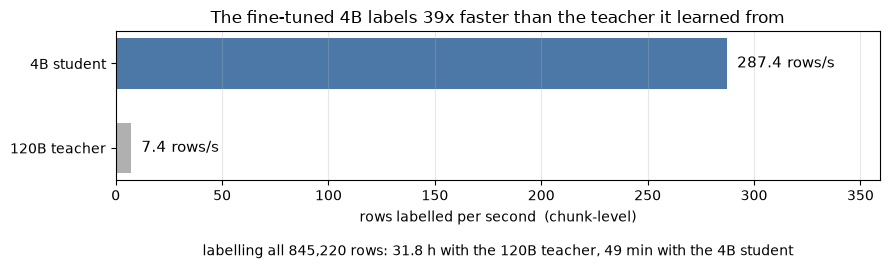

,granularity,epoch,macro_f1,floor,gainer f1,gainer precision,gainer recall,loser f1,loser precision,loser recall,irrelevant f1,irrelevant precision,irrelevant recall
0,chunk,0,0.5986,0.3160,0.5292,0.4159,0.7271,0.3379,0.2970,0.3920,0.9287,0.9664,0.8938
1,chunk,3,0.8005,0.3160,0.8036,0.8531,0.7595,0.6200,0.8267,0.4960,0.9780,0.9699,0.9862
2,chunk,5,0.8311,0.3160,0.7960,0.8135,0.7792,0.7303,0.7586,0.7040,0.9669,0.9745,0.9594
3,sentence,0,0.7295,0.3099,0.6674,0.6299,0.7096,0.5757,0.4858,0.7064,0.9454,0.9595,0.9318
4,sentence,3,0.8660,0.3099,0.8539,0.8662,0.8419,0.7673,0.8333,0.7110,0.9767,0.9730,0.9805
5,sentence,5,0.8572,0.3099,0.8392,0.8387,0.8397,0.7576,0.7778,0.7385,0.9747,0.9740,0.9754


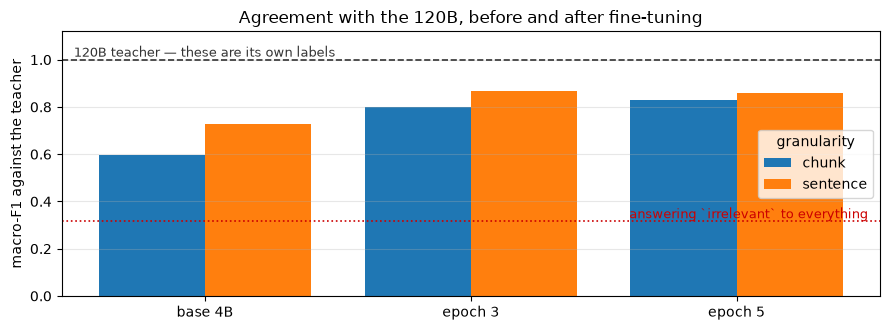

In [18]:
speed = driver.labelling_speed(RUN)
agreement = driver.scores(RUN, driver.granularities(GRANULARITY))

total = speed.loc["total"]
rates = total[["teacher rows/s", "student rows/s"]]
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(["120B teacher", "4B student"], rates,
               color=["#b0b0b0", "#4c78a8"], height=0.6)
for bar, value in zip(bars, rates):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  {value:.1f} rows/s", va="center", fontsize=11)
ax.set_xlabel(f"rows labelled per second  ({speed.attrs['granularity']}-level)\n\n"
              f"labelling all {total['rows']:,.0f} rows: "
              f"{total['teacher hours']:.1f} h with the 120B teacher, "
              f"{60 * total['student hours']:.0f} min with the 4B student")
ax.set_xlim(0, rates.max() * 1.25)
ax.set_title(f"The fine-tuned 4B labels {speed.attrs['speedup']:.0f}x faster "
             f"than the teacher it learned from")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

display(agreement)

blocks = list(agreement.groupby("granularity"))
width = 0.8 / max(len(blocks), 1)
fig, ax = plt.subplots(figsize=(9, 3.4))
names = []
for offset, (granularity, block) in enumerate(blocks):
    block = block.sort_values("epoch")
    names = ["base 4B" if e == 0 else f"epoch {e:.0f}" for e in block["epoch"]]
    ax.bar([i + offset * width for i in range(len(block))], block["macro_f1"],
           width=width, label=granularity)
ax.axhline(1.0, ls="--", color="#333", lw=1.2)
ax.text(0.01, 1.0, " 120B teacher — these are its own labels",
        transform=ax.get_yaxis_transform(), va="bottom", fontsize=9, color="#333")
floor = agreement["floor"].dropna()
if len(floor):
    ax.axhline(floor.max(), ls=":", color="#c00", lw=1.2)
    ax.text(0.99, floor.max(), "answering `irrelevant` to everything ",
            transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=9,
            color="#c00")
ax.set_xticks([i + width * (len(blocks) - 1) / 2 for i in range(len(names))], names)
ax.set_ylim(0, 1.12)
ax.set_ylabel("macro-F1 against the teacher")
ax.set_title("Agreement with the 120B, before and after fine-tuning")
ax.legend(title="granularity")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


---
## Part 3: Signal

Before a portfolio is built on the labels, one question: are they predictive at all?

The **Information Coefficient** is a rank correlation between the signal and the forward
market-neutral return, taken over every `(date, entity)` the signal touches. It reads the
labels directly — no leg size, no position cap, no book. That is the point of running it
here rather than after the backtest: below roughly 10-20% coverage a fixed-leg book is thin
and one-sided by construction, so its information ratio measures portfolio construction as
much as signal. The IC is immune to that.

**The coverage bins.** The curve's x axis is how much of the *retrieval* was labelled, on a
fixed scale: 1, 2, 5, 10, 20, 30 … 100%. A run reaches the bins at or under its own
coverage and no further — the wider ones are not weaker numbers, they are rows the student
was never shown. At `TOP_FRACTION = 0.2` that is five points: 1, 2, 5, 10 and 20.

**Bring your own prices.** From here on the pipeline needs daily returns, and it reads them
from a **price cache** you provide: two files in `PRICE_CACHE`, and nothing else is consulted.

```
prices_cache/
  prices.parquet
  prices.meta.json
```

`prices.parquet` holds one row per company per trading day:

| column | type | |
|---|---|---|
| `date` | date | the trading day |
| `entity_id` | string | ravenpack identification id |
| `return` | float | total return that day, in percent: `1.5` is +1.5% |
| `volume` | number | only `0` means anything: it discards that row's return |


The window has to be wider than your search. At least ten days before `search.start_date`,
and up to `search.end_date`: the backtest asks for that, and a cache that stops short of it
is incomplete, and the run stops there. The IC needs more at the end: twenty-one trading days
after its last signal, for the one-month horizon;
without them the IC still runs, and leaves the final month of signals out.

`prices.meta.json` says which dates the parquet covers, so the cache can tell a window it
holds from one it does not. This is the file it reads to decide, not the parquet — an
interval narrower than the window above counts as incomplete even if the rows are there:

```json
{
  "intervals": [{"start": "2015-12-22", "end": "2026-10-02"}]
}
```


In [19]:
PRICE_CACHE = REPO_ROOT / "prices_cache"   # the two files above

# --end is the last signal date the IC reads: the price cache has to hold
# 21 trading days after it, for the one-month horizon.
driver.stage(RUN, "ic", "--price-cache", PRICE_CACHE, "--end", "2026-09-02");


$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output ic --price-cache /work/bigdata-dataset-generation/prices_cache --end 2026-09-02

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output
experiment: chunk.combined

coverage of the retrieval, per content type: news 20.0%, transcripts 20.0%
bins this run can reach (<= 20.0%): [1, 2, 5, 10, 20]
window ends 2026-09-02 (backtest.end): signals after it are left out
the price cache does not reach 2026-10-12; asking to 2026-10-03, which still covers the one-month horizon
prices: 2,633,223 rows, 1,690 entities, 2016-01-04 .. 2026-10-02
     32,885 of 42,237 rows are ['irrelevant'] and carry no position
[chunk 1%] 42,237 labelled rows -> 7,465 signal days
  [chunk 1%] smoothing: 7 half-lives
     68,790 of 84,475 rows are ['irrelevant'] and carry no posit

### 3.1 Is the signal predictive

One line per bin and horizon. An IC in the low hundredths is what a per-row signal looks
like; what matters is the sign, and how it moves as coverage widens.


horizon                       1d      1m      1w
granularity coverage_pct                        
chunk       1             0.0450  0.0344  0.0298
            2             0.0354  0.0273  0.0260
            5             0.0251  0.0182  0.0211
            10            0.0215  0.0126  0.0173
            20            0.0213  0.0068  0.0147
sentence    1             0.0531  0.0327  0.0348
            2             0.0359  0.0202  0.0252
            5             0.0225  0.0043  0.0119
            10            0.0226  0.0044  0.0132
            20            0.0181  0.0023  0.0088

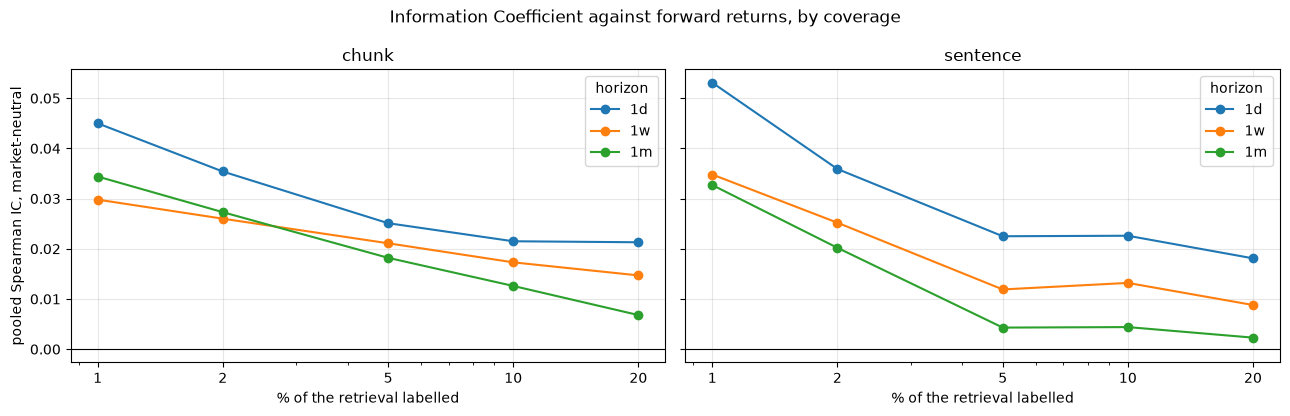

In [20]:
ic = pd.read_parquet(RUN / "ic" / "ic.parquet")
display(ic.pivot_table(index=["granularity", "coverage_pct"], columns="horizon",
                       values="ic").round(4))

books = sorted(ic["granularity"].unique())
fig, axes = plt.subplots(1, len(books), figsize=(6.5 * len(books), 4.2), sharey=True,
                         squeeze=False)
for ax, granularity in zip(axes[0], books):
    block = ic[ic["granularity"] == granularity]
    for horizon in [h for h in ("1d", "1w", "1m") if h in set(block["horizon"])]:
        line = block[block["horizon"] == horizon].sort_values("coverage_pct")
        ax.plot(line["coverage_pct"], line["ic"], marker="o", label=horizon)
    ax.set_title(granularity)
    ax.set_xscale("log")
    ax.set_xticks(sorted(block["coverage_pct"].unique()))
    ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
    ax.set_xlabel("% of the retrieval labelled")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(alpha=0.3)
    ax.legend(title="horizon")
axes[0][0].set_ylabel("pooled Spearman IC, market-neutral")
fig.suptitle("Information Coefficient against forward returns, by coverage")
fig.tight_layout()
plt.show()


### 3.2 How long a label should stay on

A label is an event: the passage was published on one day, and the raw signal fires for that
day only. Smoothing lets it decay with a half-life instead, and asks whether the information
outlives the event. This one does go through the real backtest engine, on CPU, once per
half-life per bin.


half_life                   0      1      2      7      30     90     180
granularity coverage_pct                                                 
chunk       1             1.211  1.048  0.937  0.606  0.317  0.156  0.104
            5             0.840  1.055  0.992  0.616  0.494  0.257  0.168
            20            0.950  0.908  0.733  0.568  0.306  0.033 -0.048
sentence    1             1.545  1.110  0.966  0.601  0.462  0.434  0.344
            5             0.960  0.755  0.535  0.353  0.423  0.456  0.378
            20            0.974  1.177  1.106  0.855  0.372  0.152 -0.019

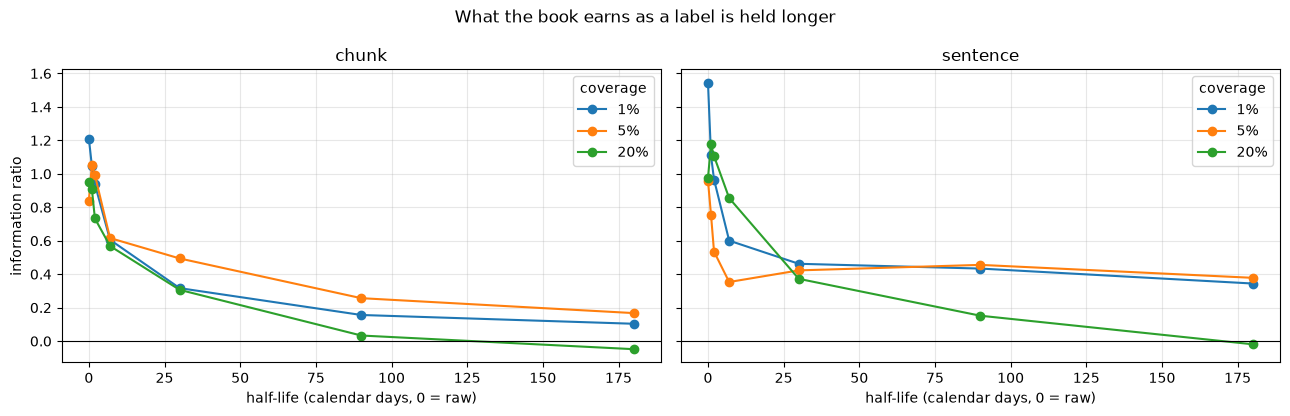

In [21]:
sweep = pd.read_parquet(RUN / "ic" / "smoothing.parquet")
display(sweep.pivot_table(index=["granularity", "coverage_pct"], columns="half_life",
                          values="ir").round(3))

books = sorted(sweep["granularity"].unique())
fig, axes = plt.subplots(1, len(books), figsize=(6.5 * len(books), 4.2), sharey=True,
                         squeeze=False)
for ax, granularity in zip(axes[0], books):
    block = sweep[sweep["granularity"] == granularity]
    for coverage in sorted(block["coverage_pct"].unique()):
        line = block[block["coverage_pct"] == coverage].sort_values("half_life")
        ax.plot(line["half_life"], line["ir"], marker="o", label=f"{coverage}%")
    ax.set_title(granularity)
    ax.set_xlabel("half-life (calendar days, 0 = raw)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(alpha=0.3)
    ax.legend(title="coverage")
axes[0][0].set_ylabel("information ratio")
fig.suptitle("What the book earns as a label is held longer")
fig.tight_layout()
plt.show()


---
## Part 4: Backtest

The backtest finds every label set you produced and builds a long/short book from each, plus one
more: **`sentiment_only`**, which uses relevance and sentiment and reads no label at all.

That one is the floor. It is what your labels have to beat to have been worth producing.

### 4.1 Point the run at prices, and choose a holding period

The same `PRICE_CACHE` Part 3 used, on the same window.

**`HALF_LIFE` is the holding period.** At 0 a label fires for the day it arrives and nothing
the day after, which leaves the book with money at work only on the days something was
published — a measured 20%-coverage run sat at 47% (chunk) and 59% (sentence) of its target
exposure, which is not caution, it is half in cash by accident, and too thin to fill both
legs. A one-day half-life lets the label decay instead, and the book fills up.

It is not free, and the table below shows both sides rather than one: every label set is
back-tested raw **and** smoothed, so the row `<name>.h1` sits next to `<name>`. On this run
that trade bought the sentence book both exposure and information ratio (0.97 → 1.18), and
cost the chunk book some information ratio (0.95 → 0.91) for its exposure. Read
`gross_exposure` next to `information_ratio`; neither means much alone.

The same half-life goes on every labelled book. Picking one per book to flatter each one is
tuning after the fact, not a rule. The floor stays raw: it already runs nearly fully
deployed, and smoothing it would only lower the bar.


In [22]:
HALF_LIFE = 1   # calendar days a label keeps half its weight; 0 is the raw signal

driver.stage(RUN, "backtest", "--price-cache", PRICE_CACHE, "--half-life", HALF_LIFE)
display(driver.headline(RUN))


$ /work/bigdata-dataset-generation/.venv/bin/python -m distill.cli --run /work/bigdata-dataset-generation/output backtest --price-cache /work/bigdata-dataset-generation/prices_cache --half-life 1 --end 2026-10-01

config : /work/bigdata-dataset-generation/config/distill.yaml
theme  : market_share (market share position)   definition e46c77c95302bf17
run    : /work/bigdata-dataset-generation/output

class signs from the theme: {'gainer': 1.0, 'loser': -1.0, 'irrelevant': 0.0}
trading-date rule: 15:30 America/New_York cut-off, then roll forward to the next business day
window ends 2026-10-01 (backtest.end): signals after it are left out
label sets found: ['chunk.combined', 'sentence.combined']

BOOK  chunk.combined   from /work/bigdata-dataset-generation/output/corpus_labels/chunk.combined/corpus.parquet
844,749 labelled rows joined to their dates; label mix {'irrelevant': 765365, 'gainer': 67063, 'loser': 12321}
79,384 of them carry a signal class
     765,365 of 844,749 rows are ['irre

,book,signal,ir,ann_return,volatility,gross_exposure,net_exposure
0,chunk.combined,smoothed_h1,0.9085,0.0658,0.0724,0.9173,0.0741
1,sentence.combined,smoothed_h1,1.1767,0.0863,0.0733,0.9700,0.0273
2,chunk.combined,raw,0.9496,0.0588,0.0619,0.4731,0.2031
3,sentence.combined,raw,0.9741,0.0675,0.0692,0.5870,0.1988
4,sentiment_only,raw,0.4060,0.0378,0.0931,0.9939,0.0053


Both labelled books at the same one-day rule, each against its own raw signal for
reference. The floor is the same portfolio construction driven by relevance × sentiment
alone, reading no classification label.


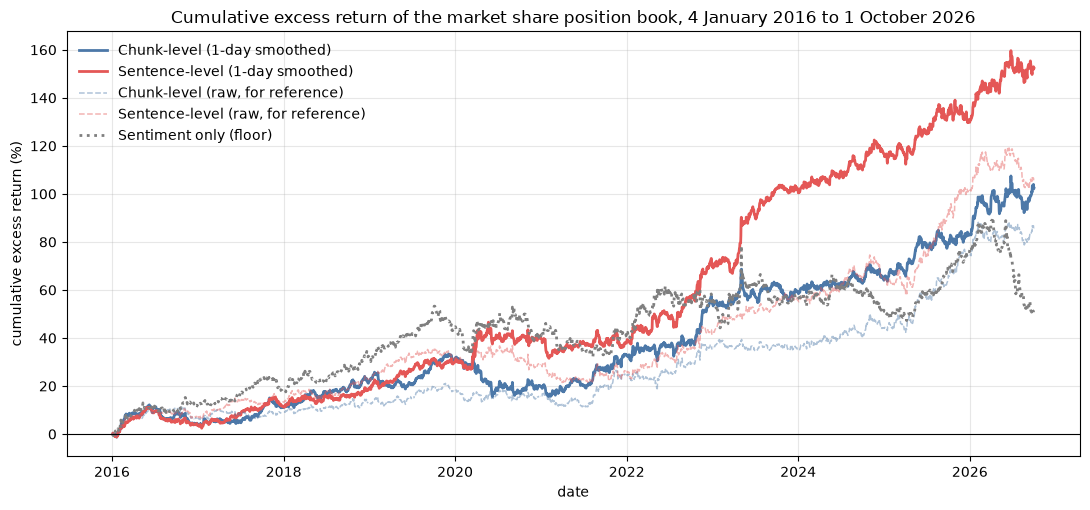

In [23]:
curves = driver.cumulative(RUN)

COLOUR = {"Chunk": "#4c78a8", "Sentence": "#e45756"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for name in curves.columns:
    floor = "floor" in name
    smoothed = "smoothed" in name
    colour = "#7f7f7f" if floor else COLOUR.get(name.split("-")[0], "#4c78a8")
    ax.plot(curves.index, 100 * curves[name], label=name, color=colour,
            linewidth=2.0 if smoothed or floor else 1.1,
            linestyle="-" if smoothed else (":" if floor else "--"),
            alpha=1.0 if smoothed or floor else 0.45)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("cumulative excess return (%)")
ax.set_xlabel("date")
ax.set_title(f"Cumulative excess return of the {THEME_TITLE} book, "
             f"{curves.index[0]:%-d %B %Y} to {curves.index[-1]:%-d %B %Y}")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()
